In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib
import gc

import pyarrow.parquet as pq

from pathlib import Path

from sklearn.linear_model import LogisticRegression

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    precision_recall_curve,
    roc_curve
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

DATA_PATH = Path("../data/processed")
MODEL_PATH = Path("../models")
RESULTS_PATH = Path("../reports/results")

MODEL_PATH.mkdir(parents=True, exist_ok=True)
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

FIGURES_PATH = Path("../reports/figures")
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        FIGURES_PATH / filename,
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()


In [2]:
with open(DATA_PATH / "feature_metadata.json", "r") as f:
    metadata = json.load(f)

feature_columns = metadata["feature_columns"]
feature_groups = metadata["feature_groups"]
target_column = metadata["target_column"]

feature_groups

{'transaction': ['type', 'amount', 'log_amount', 'recipient_is_merchant'],
 'temporal': ['hour_sin', 'hour_cos'],
 'behavioral': ['recipient_prior_count',
  'recipient_prior_total',
  'recipient_prior_mean',
  'recipient_hours_since_last',
  'recipient_is_new',
  'amount_to_recipient_mean']}

In [3]:
NEGATIVE_SAMPLE_RATE = 0.05
BATCH_SIZE = 100_000

rng = np.random.default_rng(RANDOM_STATE)

train_file = pq.ParquetFile(
    DATA_PATH / "train.parquet"
)

sampled_batches = []

population_counts = {0: 0, 1: 0}

for batch in train_file.iter_batches(
    batch_size=BATCH_SIZE,
    columns=feature_columns + [target_column]
):

    chunk = batch.to_pandas()

    fraud_mask = chunk[target_column] == 1

    population_counts[1] += int(fraud_mask.sum())
    population_counts[0] += int((~fraud_mask).sum())

    random_mask = rng.random(len(chunk)) < NEGATIVE_SAMPLE_RATE

    keep_mask = fraud_mask | random_mask

    sampled_batches.append(
        chunk.loc[keep_mask].copy()
    )

    del chunk

train_df = pd.concat(
    sampled_batches,
    ignore_index=True
)

del sampled_batches
gc.collect()

print("Original training counts:", population_counts)
print("Sampled training shape:", train_df.shape)

Original training counts: {0: 6005930, 1: 5007}
Sampled training shape: (305142, 13)


In [4]:
val_df = pd.read_parquet(
    DATA_PATH / "validation.parquet",
    columns=feature_columns + [
        target_column,
        "isFlaggedFraud"
    ]
)

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)

Training shape: (305142, 13)
Validation shape: (228103, 14)


In [5]:
for name, dataset in [
    ("Training Sample", train_df),
    ("Validation", val_df)
]:

    print(f"\n{name}")
    print(dataset[target_column].value_counts())
    print(dataset[target_column].value_counts(normalize=True))


Training Sample
isFraud
0    300135
1      5007
Name: count, dtype: int64
isFraud
0    0.983591
1    0.016409
Name: proportion, dtype: float64

Validation
isFraud
0    226551
1      1552
Name: count, dtype: int64
isFraud
0    0.993196
1    0.006804
Name: proportion, dtype: float64


In [6]:
X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_val = val_df[feature_columns]
y_val = val_df[target_column]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)

X_train: (305142, 12)
X_val: (228103, 12)


In [7]:
population_weights = np.where(
    y_train == 1,
    1.0,
    1.0 / NEGATIVE_SAMPLE_RATE
)

population_weights = (
    population_weights / population_weights.mean()
)

In [8]:
results = []
predictions = {}
trained_models = {}

def evaluate_model(
    model_name,
    y_true,
    y_score,
    amounts,
    threshold=0.5
):

    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    amounts = np.asarray(amounts)

    y_pred = (y_score >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    total_fraud_amount = amounts[y_true == 1].sum()

    detected_fraud_amount = amounts[
        (y_true == 1) & (y_pred == 1)
    ].sum()

    metrics = {
        "model": model_name,
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "average_precision": average_precision_score(
            y_true, y_score
        ),
        "roc_auc": roc_auc_score(y_true, y_score),
        "fraud_value_captured": (
            detected_fraud_amount / total_fraud_amount
            if total_fraud_amount > 0 else 0
        ),
        "true_positives": tp,
        "false_positives": fp,
        "true_negatives": tn,
        "false_negatives": fn
    }

    results.append(metrics)
    predictions[model_name] = y_score

    return pd.Series(metrics)

In [9]:
rule_predictions = val_df["isFlaggedFraud"].to_numpy()

evaluate_model(
    "PaySim Fraud Rule",
    y_val,
    rule_predictions,
    val_df["amount"]
)

model                   PaySim Fraud Rule
threshold                             0.5
accuracy                         0.993205
precision                             1.0
recall                           0.001289
f1                               0.002574
average_precision                0.008084
roc_auc                          0.500644
fraud_value_captured             0.001933
true_positives                          2
false_positives                         0
true_negatives                     226551
false_negatives                      1550
dtype: object

In [10]:
def create_preprocessor(features):

    categorical_features = [
        col for col in features
        if col == "type"
    ]

    numerical_features = [
        col for col in features
        if col not in categorical_features
    ]

    numerical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ])

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ])

    preprocessor = ColumnTransformer([
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ])

    return preprocessor

In [11]:
def create_logistic_model(features, class_weight=None):

    return Pipeline([
        (
            "preprocessor",
            create_preprocessor(features)
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight=class_weight,
                solver="lbfgs",
                random_state=RANDOM_STATE
            )
        )
    ])

In [12]:
logistic_model = create_logistic_model(
    feature_columns
)

logistic_model.fit(
    X_train,
    y_train,
    classifier__sample_weight=population_weights
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['type','amount','log_amount',...,'recipient_hours_since_last', 'recipient_is_new','amount_to_recipient_mean']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``

In [13]:
logistic_probs = logistic_model.predict_proba(
    X_val
)[:, 1]

trained_models["Logistic Regression"] = logistic_model

evaluate_model(
    "Logistic Regression",
    y_val,
    logistic_probs,
    val_df["amount"]
)

model                   Logistic Regression
threshold                               0.5
accuracy                            0.99342
precision                          0.981132
recall                             0.033505
f1                                 0.064798
average_precision                   0.39436
roc_auc                               0.931
fraud_value_captured               0.147823
true_positives                           52
false_positives                           1
true_negatives                       226550
false_negatives                        1500
dtype: object

In [14]:
balanced_model = create_logistic_model(
    feature_columns,
    class_weight="balanced"
)

balanced_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['type','amount','log_amount',...,'recipient_hours_since_last', 'recipient_is_new','amount_to_recipient_mean']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``

In [15]:
balanced_probs = balanced_model.predict_proba(
    X_val
)[:, 1]

trained_models["Balanced Logistic Regression"] = balanced_model

evaluate_model(
    "Balanced Logistic Regression",
    y_val,
    balanced_probs,
    val_df["amount"]
)

model                   Balanced Logistic Regression
threshold                                        0.5
accuracy                                    0.774554
precision                                   0.027351
recall                                      0.929768
f1                                          0.053138
average_precision                           0.326533
roc_auc                                     0.948812
fraud_value_captured                        0.986851
true_positives                                  1443
false_positives                                51316
true_negatives                                175235
false_negatives                                  109
dtype: object

In [16]:
experiments = {
    "A - Transaction Only":
        feature_groups["transaction"],

    "B - Transaction + Temporal":
        feature_groups["transaction"]
        + feature_groups["temporal"],

    "C - Transaction + Behavioral":
        feature_groups["transaction"]
        + feature_groups["behavioral"]
}

In [17]:
for experiment_name, features in experiments.items():

    print(f"Training {experiment_name}")
    print(f"Number of features: {len(features)}")

    model = create_logistic_model(
        features,
        class_weight="balanced"
    )

    model.fit(
        X_train[features],
        y_train
    )

    probabilities = model.predict_proba(
        X_val[features]
    )[:, 1]

    trained_models[experiment_name] = model

    metrics = evaluate_model(
        experiment_name,
        y_val,
        probabilities,
        val_df["amount"]
    )

    print(metrics[[
        "precision",
        "recall",
        "f1",
        "average_precision",
        "roc_auc"
    ]])

    gc.collect()

Training A - Transaction Only
Number of features: 4
precision            0.025824
recall               0.873711
f1                   0.050165
average_precision    0.095399
roc_auc              0.905747
dtype: object
Training B - Transaction + Temporal
Number of features: 6
precision            0.035787
recall               0.871778
f1                   0.068752
average_precision    0.168465
roc_auc              0.932775
dtype: object
Training C - Transaction + Behavioral
Number of features: 10
precision            0.018837
recall               0.954897
f1                   0.036944
average_precision    0.163731
roc_auc              0.917962
dtype: object


In [18]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "average_precision",
    ascending=False
).reset_index(drop=True)

results_df.round(6)

,model,threshold,accuracy,precision,recall,f1,average_precision,roc_auc,fraud_value_captured,true_positives,false_positives,true_negatives,false_negatives
0,Logistic Regression,0.5,0.993420,0.981132,0.033505,0.064798,0.394360,0.931000,0.147823,52,1,226550,1500
1,Balanced Logistic Regression,0.5,0.774554,0.027351,0.929768,0.053138,0.326533,0.948812,0.986851,1443,51316,175235,109
2,B - Transaction + Temporal,0.5,0.839314,0.035787,0.871778,0.068752,0.168465,0.932775,0.972272,1353,36454,190097,199
3,C - Transaction + Behavioral,0.5,0.661271,0.018837,0.954897,0.036944,0.163731,0.917962,0.993247,1482,77195,149356,70
4,A - Transaction Only,0.5,0.774882,0.025824,0.873711,0.050165,0.095399,0.905747,0.989581,1356,51154,175397,196
5,PaySim Fraud Rule,0.5,0.993205,1.000000,0.001289,0.002574,0.008084,0.500644,0.001933,2,0,226551,1550


In [19]:
comparison_columns = [
    "model",
    "average_precision",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "fraud_value_captured",
    "false_positives"
]

results_df[comparison_columns].round(6)

,model,average_precision,roc_auc,precision,recall,f1,fraud_value_captured,false_positives
0,Logistic Regression,0.394360,0.931000,0.981132,0.033505,0.064798,0.147823,1
1,Balanced Logistic Regression,0.326533,0.948812,0.027351,0.929768,0.053138,0.986851,51316
2,B - Transaction + Temporal,0.168465,0.932775,0.035787,0.871778,0.068752,0.972272,36454
3,C - Transaction + Behavioral,0.163731,0.917962,0.018837,0.954897,0.036944,0.993247,77195
4,A - Transaction Only,0.095399,0.905747,0.025824,0.873711,0.050165,0.989581,51154
5,PaySim Fraud Rule,0.008084,0.500644,1.000000,0.001289,0.002574,0.001933,0


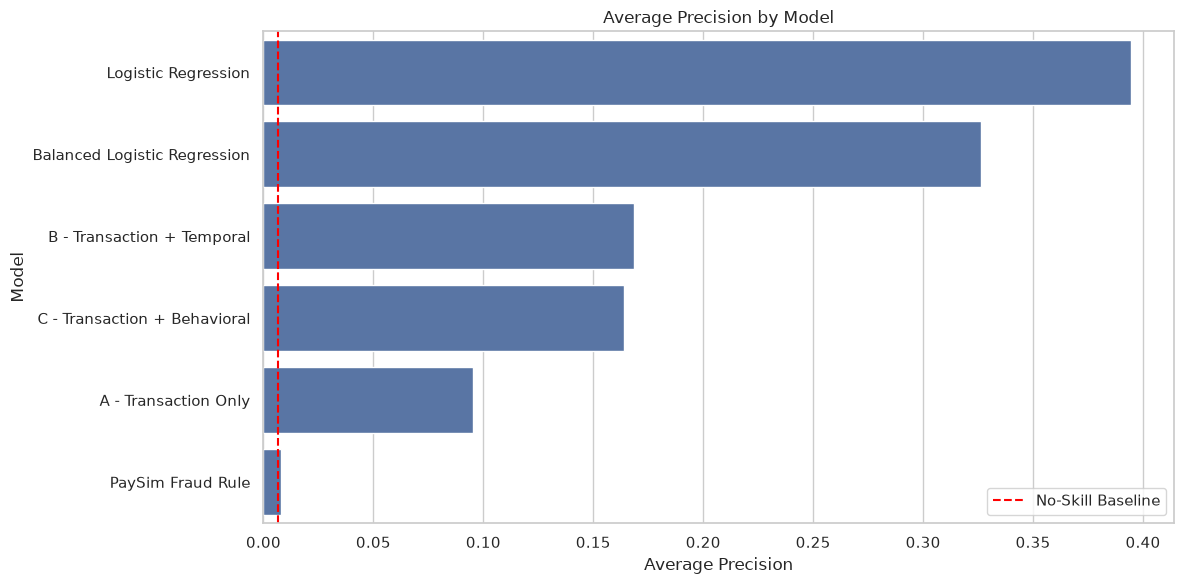

In [20]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="average_precision",
    y="model"
)

plt.axvline(
    y_val.mean(),
    color="red",
    linestyle="--",
    label="No-Skill Baseline"
)

plt.title("Average Precision by Model")
plt.xlabel("Average Precision")
plt.ylabel("Model")
plt.legend()
save_plot("baseline_average_precision.png")

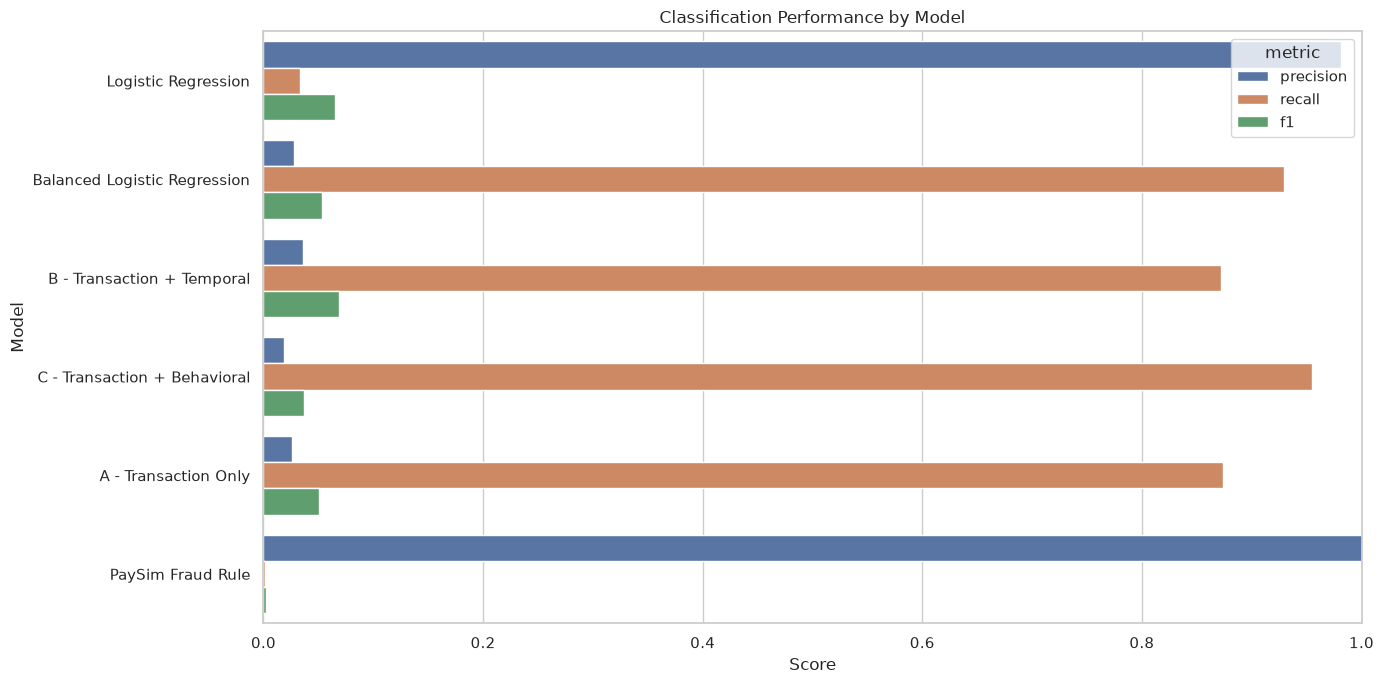

In [21]:
plot_df = results_df.melt(
    id_vars="model",
    value_vars=["precision", "recall", "f1"],
    var_name="metric",
    value_name="score"
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=plot_df,
    x="score",
    y="model",
    hue="metric"
)

plt.title("Classification Performance by Model")
plt.xlabel("Score")
plt.ylabel("Model")
plt.xlim(0, 1)
save_plot("baseline_classification_metrics.png")

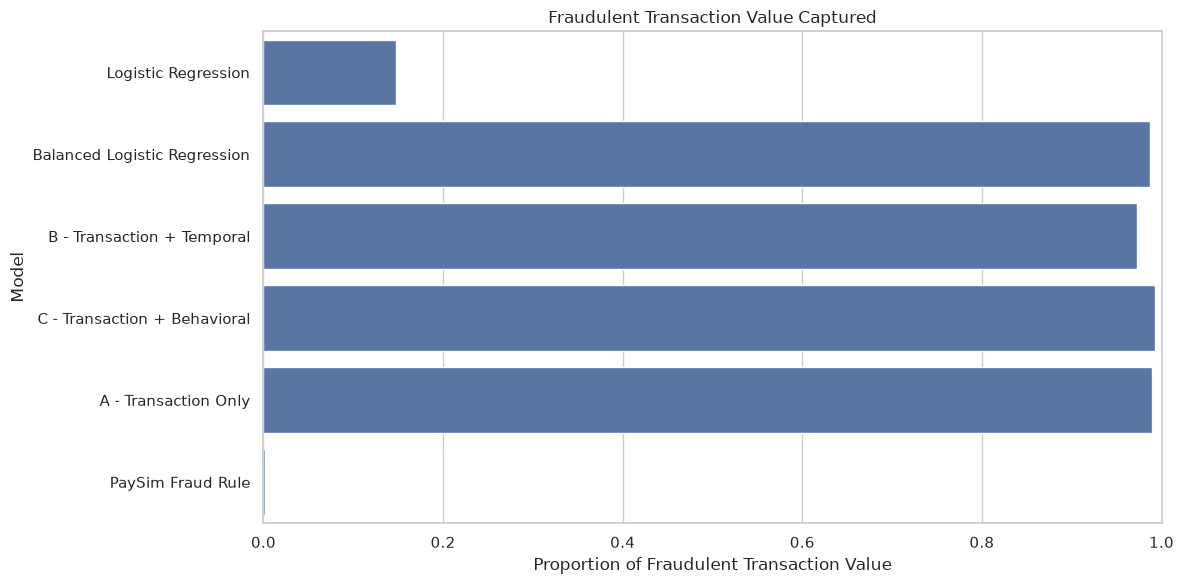

In [22]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="fraud_value_captured",
    y="model"
)

plt.title("Fraudulent Transaction Value Captured")
plt.xlabel("Proportion of Fraudulent Transaction Value")
plt.ylabel("Model")
plt.xlim(0, 1)
save_plot("baseline_fraud_value_captured.png")

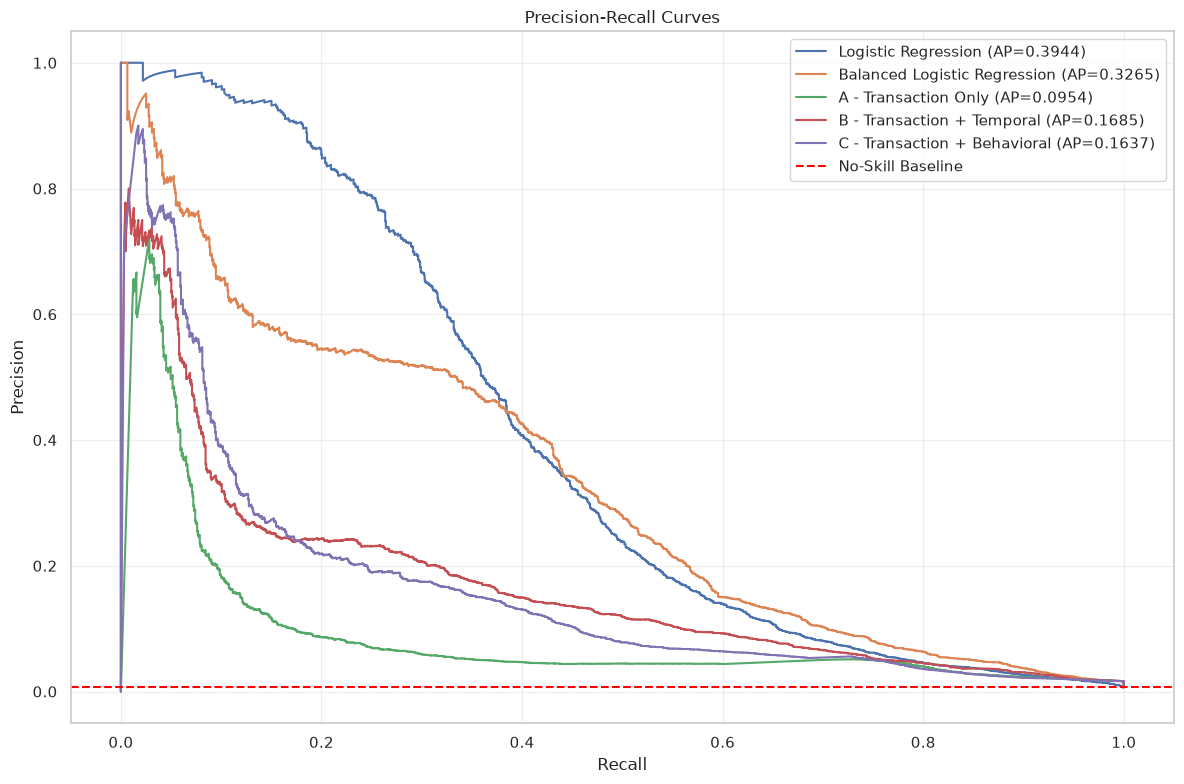

In [23]:
plt.figure(figsize=(12, 8))

for model_name, probabilities in predictions.items():

    if model_name == "PaySim Fraud Rule":
        continue

    precision, recall, _ = precision_recall_curve(
        y_val,
        probabilities
    )

    ap = average_precision_score(
        y_val,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (AP={ap:.4f})"
    )

plt.axhline(
    y_val.mean(),
    color="red",
    linestyle="--",
    label="No-Skill Baseline"
)

plt.title("Precision-Recall Curves")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(alpha=0.3)
save_plot("baseline_validation_precision_recall.png")

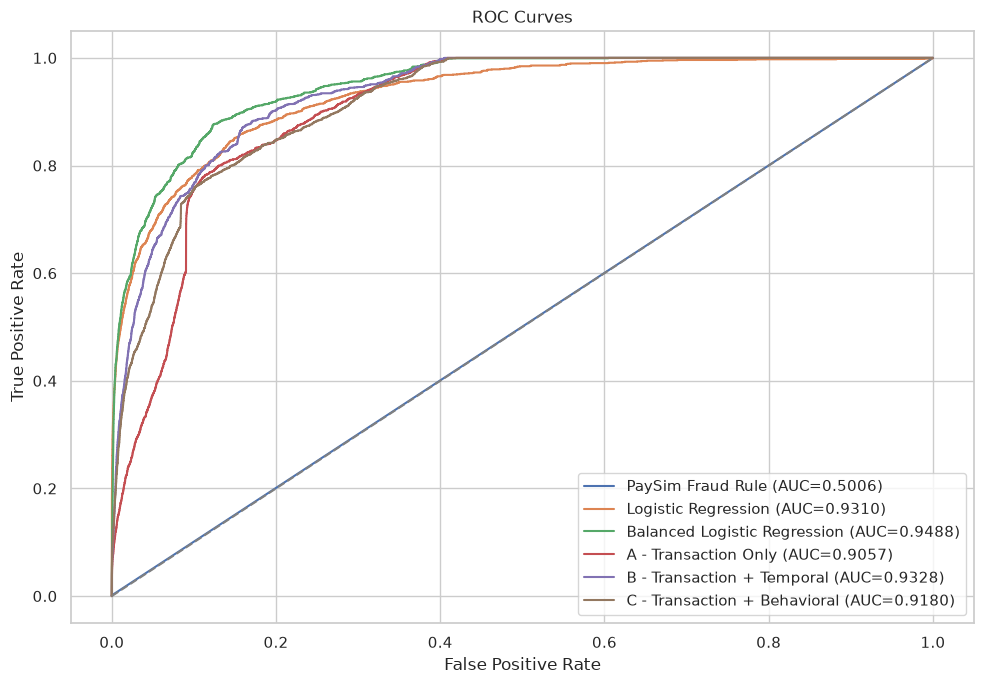

In [24]:
plt.figure(figsize=(10, 7))

for model_name, probabilities in predictions.items():

    fpr, tpr, _ = roc_curve(
        y_val,
        probabilities
    )

    auc = roc_auc_score(
        y_val,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC={auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.title("ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
ablation_names = [
    "A - Transaction Only",
    "B - Transaction + Temporal",
    "C - Transaction + Behavioral",
    "Balanced Logistic Regression"
]

ablation_results = (
    results_df
    .set_index("model")
    .loc[ablation_names]
    .reset_index()
    .copy()
)

ablation_results["model"] = [
    "Transaction Only",
    "Transaction + Temporal",
    "Transaction + Behavioral",
    "All Features"
]

baseline_ap = ablation_results.loc[
    0, "average_precision"
]

ablation_results["ap_improvement"] = (
    ablation_results["average_precision"] - baseline_ap
)

ablation_results["relative_improvement_pct"] = (
    ablation_results["ap_improvement"] /
    baseline_ap * 100
)

ablation_results[[
    "model",
    "average_precision",
    "roc_auc",
    "ap_improvement",
    "relative_improvement_pct"
]].round(6)

,model,average_precision,roc_auc,ap_improvement,relative_improvement_pct
0,Transaction Only,0.095399,0.905747,0.000000,0.000000
1,Transaction + Temporal,0.168465,0.932775,0.073066,76.589870
2,Transaction + Behavioral,0.163731,0.917962,0.068332,71.627116
3,All Features,0.326533,0.948812,0.231134,242.281444


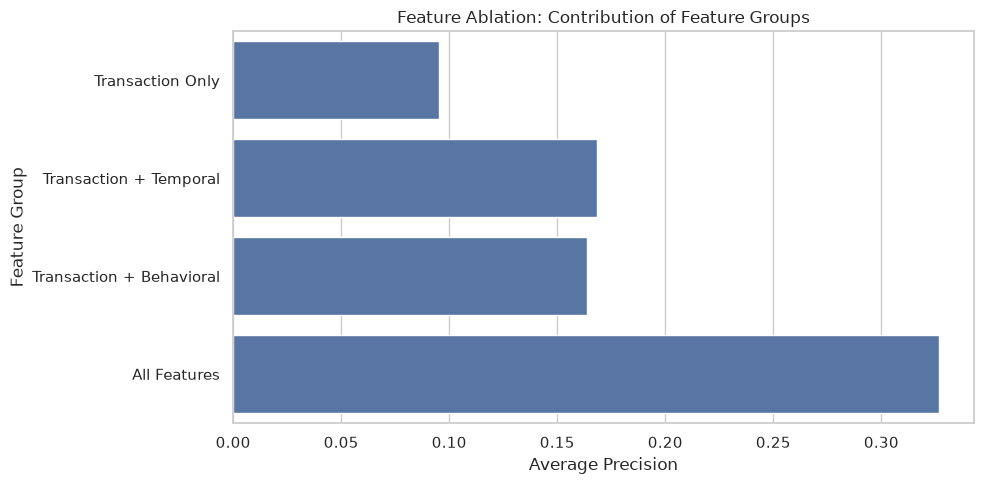

In [26]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=ablation_results,
    x="average_precision",
    y="model"
)

plt.title("Feature Ablation: Contribution of Feature Groups")
plt.xlabel("Average Precision")
plt.ylabel("Feature Group")
save_plot("baseline_feature_ablation.png")

In [27]:
ml_results = results_df[
    results_df["model"].isin(trained_models.keys())
]

best_model_name = ml_results.iloc[0]["model"]

best_model = trained_models[best_model_name]

best_model_probs = predictions[best_model_name]

print("Best Baseline Model:", best_model_name)

ml_results.iloc[0]

Best Baseline Model: Logistic Regression


model                   Logistic Regression
threshold                               0.5
accuracy                            0.99342
precision                          0.981132
recall                             0.033505
f1                                 0.064798
average_precision                   0.39436
roc_auc                               0.931
fraud_value_captured               0.147823
true_positives                           52
false_positives                           1
true_negatives                       226550
false_negatives                        1500
Name: 0, dtype: object

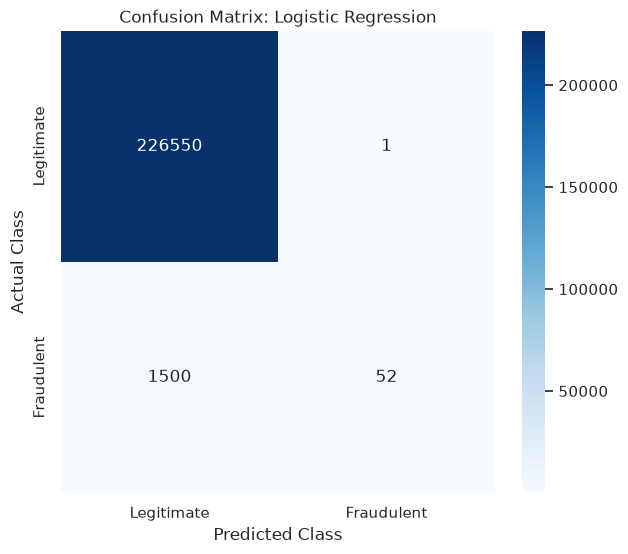

In [28]:
best_model_preds = (
    best_model_probs >= 0.5
).astype(int)

cm = confusion_matrix(
    y_val,
    best_model_preds,
    labels=[0, 1]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.title(f"Confusion Matrix: {best_model_name}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [29]:
transformed_feature_names = (
    best_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = (
    best_model
    .named_steps["classifier"]
    .coef_[0]
)

coefficient_df = pd.DataFrame({
    "feature": transformed_feature_names,
    "coefficient": coefficients
})

coefficient_df["absolute_coefficient"] = (
    coefficient_df["coefficient"].abs()
)

coefficient_df.sort_values(
    "absolute_coefficient",
    ascending=False
)

,feature,coefficient,absolute_coefficient
14,categorical__type_CASH_IN,-3.145986,3.145986
17,categorical__type_PAYMENT,-2.986594,2.986594
4,numerical__hour_cos,1.228114,1.228114
1,numerical__log_amount,1.067824,1.067824
2,numerical__recipient_is_merchant,-1.063795,1.063795
3,numerical__hour_sin,0.864322,0.864322
15,categorical__type_CASH_OUT,-0.631004,0.631004
18,categorical__type_TRANSFER,-0.495835,0.495835
6,numerical__recipient_prior_total,-0.398566,0.398566
7,numerical__recipient_prior_mean,-0.370379,0.370379


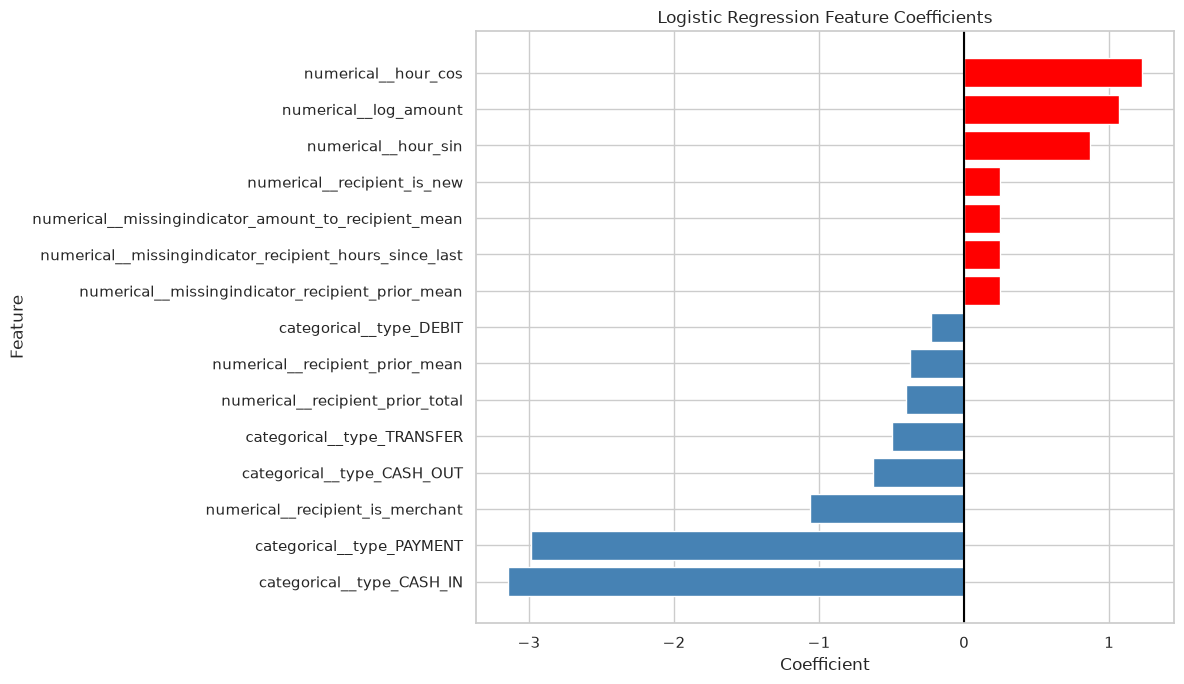

In [30]:
top_coefficients = (
    coefficient_df
    .nlargest(15, "absolute_coefficient")
    .sort_values("coefficient")
)

plt.figure(figsize=(12, 7))

colors = [
    "red" if value > 0 else "steelblue"
    for value in top_coefficients["coefficient"]
]

plt.barh(
    top_coefficients["feature"],
    top_coefficients["coefficient"],
    color=colors
)

plt.axvline(0, color="black")

plt.title("Logistic Regression Feature Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
save_plot("baseline_logistic_coefficients.png")

In [31]:
joblib.dump(
    best_model,
    MODEL_PATH / "baseline_logistic_regression.joblib"
)

['../models/baseline_logistic_regression.joblib']

In [32]:
results_df.to_csv(
    RESULTS_PATH / "baseline_model_results.csv",
    index=False
)

ablation_results.to_csv(
    RESULTS_PATH / "baseline_ablation_results.csv",
    index=False
)

coefficient_df.to_csv(
    RESULTS_PATH / "baseline_coefficients.csv",
    index=False
)

In [33]:
model_metadata = {
    "model_name": best_model_name,
    "model_type": "LogisticRegression",
    "feature_columns": best_model.feature_names_in_.tolist(),
    "class_weight": (
        best_model.named_steps["classifier"].class_weight
    ),
    "selection_metric": "average_precision",
    "validation_average_precision": float(
        ml_results.iloc[0]["average_precision"]
    ),
    "validation_roc_auc": float(
        ml_results.iloc[0]["roc_auc"]
    ),
    "decision_threshold": 0.5,
    "threshold_optimized": False,
    "negative_sample_rate": NEGATIVE_SAMPLE_RATE,
    "training_sample_size": len(train_df),
    "random_state": RANDOM_STATE,
    "test_set_evaluated": False
}

with open(
    MODEL_PATH / "baseline_model_metadata.json",
    "w"
) as f:
    json.dump(model_metadata, f, indent=4)

## Key Findings

### Training Strategy and Class Imbalance
- The original training dataset contains 6,010,937 transactions,
  including 5,007 fraudulent transactions.
- Implemented memory-efficient batch reading using PyArrow to
  process 100,000 transactions at a time.
- Applied random majority-class undersampling with a 5% legitimate
  transaction retention rate while preserving all fraudulent
  transactions.
- The resulting training dataset contains 305,142 transactions:
  - 300,135 legitimate transactions
  - 5,007 fraudulent transactions
- Reduced the training dataset size by approximately 94.92% without
  discarding any fraudulent examples.
- Fraud prevalence increased from 0.0833% in the original training
  dataset to 1.6409% in the sampled training dataset.
- Applied inverse probability weighting to approximately restore
  the original class contributions for ordinary logistic regression.
- Retained the complete validation dataset of 228,103 transactions
  to evaluate performance under its natural class distribution.
- The test dataset was not used during model development.

### Existing Rule-Based Benchmark Performance
- The existing PaySim fraud detection rule correctly identified
  only 2 of the 1,552 fraudulent validation transactions.
- The rule generated zero false positives but missed 1,550
  fraudulent transactions.
- Achieved the following performance:
  - Precision: 100.00%
  - Recall: 0.1289%
  - F1-score: 0.002574
  - Average Precision: 0.008084
  - ROC-AUC: 0.500644
  - Fraudulent transaction value captured: 0.1933%
- The rule demonstrates high precision but extremely limited
  fraud detection capability.

### Logistic Regression Performance
- Ordinary logistic regression achieved the highest validation
  Average Precision among all evaluated models.
- Model performance at a threshold of 0.5:
  - Average Precision: 0.394360
  - ROC-AUC: 0.931000
  - Accuracy: 99.3420%
  - Precision: 98.1132%
  - Recall: 3.3505%
  - F1-score: 0.064798
  - Fraudulent transaction value captured: 14.7823%
- Correctly identified 52 fraudulent transactions while generating
  only one false positive.
- Despite strong ranking performance and precision, the default
  classification threshold results in extremely low fraud recall.
- The model was selected as the best baseline based on validation
  Average Precision rather than threshold-dependent metrics.

### Impact of Balanced Class Weighting
- Balanced logistic regression substantially increased fraud recall
  by assigning equal total importance to both classes.
- Model performance at a threshold of 0.5:
  - Average Precision: 0.326533
  - ROC-AUC: 0.948812
  - Precision: 2.7351%
  - Recall: 92.9768%
  - F1-score: 0.053138
  - Fraudulent transaction value captured: 98.6851%
- Correctly identified 1,443 fraudulent transactions but generated
  51,316 false positives.
- Class weighting improved recall and ROC-AUC but reduced precision
  and Average Precision relative to ordinary logistic regression.
- The large number of false positives would create a substantial
  investigation burden in a practical fraud detection system.
- Class weighting alone does not guarantee improved overall
  fraud detection performance.

### Feature Ablation Results

All feature ablation experiments used balanced logistic regression
with consistent training data and model configurations.

| Feature Group | Average Precision | ROC-AUC | Relative AP Improvement |
|---|---:|---:|---:|
| Transaction Only | 0.095399 | 0.905747 | Baseline |
| Transaction + Temporal | 0.168465 | 0.932775 | 76.59% |
| Transaction + Behavioral | 0.163731 | 0.917962 | 71.63% |
| All Features | 0.326533 | 0.948812 | 242.28% |

- Temporal features improved Average Precision by 76.59%
  relative to transaction-only features.
- Historical recipient behavioral features improved Average
  Precision by 71.63%.
- Combining transaction, temporal, and behavioral features
  achieved the strongest balanced logistic regression performance.
- The complete feature set improved Average Precision by
  242.28% relative to the transaction-only baseline.
- These results demonstrate that the engineered features provide
  incremental predictive value beyond basic transaction attributes.

### Precision-Recall Trade-offs
- Ordinary logistic regression achieved high precision but low
  recall at the default classification threshold.
- Balanced logistic regression achieved high recall but generated
  a substantial number of false-positive alerts.
- The transaction and behavioral feature model achieved the
  highest recall at approximately 95.49%.
- The transaction and temporal feature model achieved the
  highest F1-score at approximately 0.0688.
- Average Precision was prioritized for model selection because
  it evaluates ranking performance across classification thresholds.
- Future experiments should optimize decision thresholds using
  validation data and operational cost assumptions.

### Fraudulent Transaction Value Captured
- The existing PaySim rule detected approximately 0.19% of
  fraudulent transaction value.
- Ordinary logistic regression detected approximately 14.78%.
- Balanced logistic regression detected approximately 98.69%.
- The transaction and behavioral feature model detected
  approximately 99.32% of fraudulent transaction value, but
  generated 77,195 false positives.
- Financial transaction value provides an important complement
  to conventional classification metrics.
- Detected fraudulent transaction value should not be interpreted
  directly as realized financial losses prevented.

### Feature Interpretability
- Logistic regression coefficients provide insight into the
  relationships between engineered features and predicted fraud risk.
- CASH_IN and PAYMENT transaction types exhibited large negative
  coefficients, consistent with the fraud patterns observed during EDA.
- Log-transformed transaction amount exhibited a positive coefficient,
  indicating an association with higher predicted fraud risk.
- Cyclical temporal features exhibited relatively large coefficients,
  suggesting that simulated transaction timing contributes to
  predictive performance.
- New recipient status was positively associated with predicted
  fraud risk.
- Historical recipient activity and cumulative transaction amounts
  generally exhibited negative coefficients.
- Several missing-value indicators share the same coefficient as
  the new recipient indicator, suggesting feature redundancy.
- Coefficients represent conditional model associations rather than
  causal effects and should be interpreted carefully because of
  feature scaling, correlation, and regularization.

### Model Limitations
- Random undersampling discards approximately 95% of legitimate
  training transactions and may remove useful information.
- Inverse probability weighting approximates the original training
  objective, but preprocessing statistics are fitted on the
  undersampled dataset without sampling weights.
- Logistic regression assumes a linear relationship between
  transformed predictors and fraud log-odds.
- The model may not adequately capture complex nonlinear
  relationships and feature interactions.
- Extreme class imbalance and temporal distribution shifts
  remain significant modeling challenges.
- Predicted probabilities have not been calibrated.
- Classification thresholds have not been optimized.
- Temporal features may capture simulator-specific behavior
  rather than generalizable real-world financial patterns.
- PaySim is a synthetic dataset, limiting conclusions about
  real-world fraud detection performance.
- Final generalization performance remains unknown because
  the held-out test dataset has not been evaluated.

### Model Artifacts and Reproducibility
- Saved the best-performing logistic regression pipeline using
  Joblib, including its fitted preprocessing transformations.
- Exported baseline model comparison results, feature ablation
  results, and model coefficients in CSV format.
- Configured six selected baseline evaluation figures for export to
  `reports/figures/`, covering model comparison, fraud value,
  precision-recall performance, feature ablation, and coefficients.
- Used a fixed random seed to improve experimental reproducibility.
- Preserved the chronological validation strategy established
  during feature engineering.

### Implications for Advanced Model Development
- Use ordinary logistic regression with an Average Precision
  of 0.394360 as the primary ML baseline.
- Retain the complete engineered feature set based on the
  positive feature ablation results.
- Investigate gradient-boosted decision tree models such as
  XGBoost and LightGBM to capture nonlinear feature interactions.
- Evaluate alternative class imbalance handling strategies.
- Investigate the relationship between training sample size,
  computational requirements, and model performance.
- Perform hyperparameter optimization using validation data
  without accessing the test dataset.
- Evaluate probability calibration and cost-sensitive
  classification thresholds.
- Compare advanced models using Average Precision, ROC-AUC,
  precision, recall, F1-score, false positives, and fraudulent
  transaction value captured.

## Conclusion

The baseline modeling phase successfully established machine
learning and rule-based benchmarks for fraud detection using
the PaySim dataset.

Ordinary logistic regression achieved the strongest validation
Average Precision of 0.394360, while balanced logistic regression
demonstrated the ability to detect a substantially larger
proportion of fraudulent transactions.

Feature ablation experiments demonstrated that combining temporal
and historical recipient behavioral features with transaction
features improved Average Precision by 242.28% relative to the
transaction-only balanced logistic regression baseline.

However, the substantial precision-recall trade-offs observed
at the default classification threshold highlight the need for
more advanced modeling, probability calibration, and cost-sensitive
decision-making.

The next phase will investigate gradient-boosted decision tree
models to capture nonlinear relationships and improve fraud
detection performance while maintaining leakage-controlled
evaluation and chronological data separation.